# Figure 1 · The galaxy sample

**Question:** What galaxies enter this study, and how are independent spatial subsets constructed?

**Status:** real sample metadata; first layout draft. No image arrays are opened.
The footprint includes held-out positions/counts to document the split design;
the property distributions use training and validation only.

**Proposed panels:** (a) accepted-object footprint, (b) candidate accounting,
(c) optical magnitude, (d) photometric redshift.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'

In [2]:
# Review controls: figure size, histogram bins, colors, export version.
FIGSIZE = (7.2, 6.0)
PROPERTY_SPLITS = ['train', 'validation']
manifest_path = DATA / 'manifest.json'
objects_path = DATA / 'objects.csv'
manifest = read_json(manifest_path)
objects = pd.read_csv(objects_path)
assert len(objects) == manifest['accepted']
assert objects.id_classic.is_unique and objects.row.is_unique
assert objects.groupby('split').size().to_dict() == manifest['split_counts']
assert manifest['accepted'] + sum(manifest['rejection_counts'].values()) == manifest['candidates']
display(pd.DataFrame({'split': list(manifest['split_counts']),
                      'galaxies': list(manifest['split_counts'].values())}))
print('Selection:', manifest['selection'])
print('Quality:', manifest['quality'])

,split,galaxies
0,train,17816
1,test,2876
2,validation,2118


Selection: lp_type==0; ACS_F814W_MAG<25; .01<ez_z_phot<3; 4<FLUX_RADIUS<500; existing dated coverage candidates
Quality: DQ==0; finite SCI and positive finite RMS<1e7; >=95% coverage each instrument; central 5x5 NISP /25x25 HR fully valid


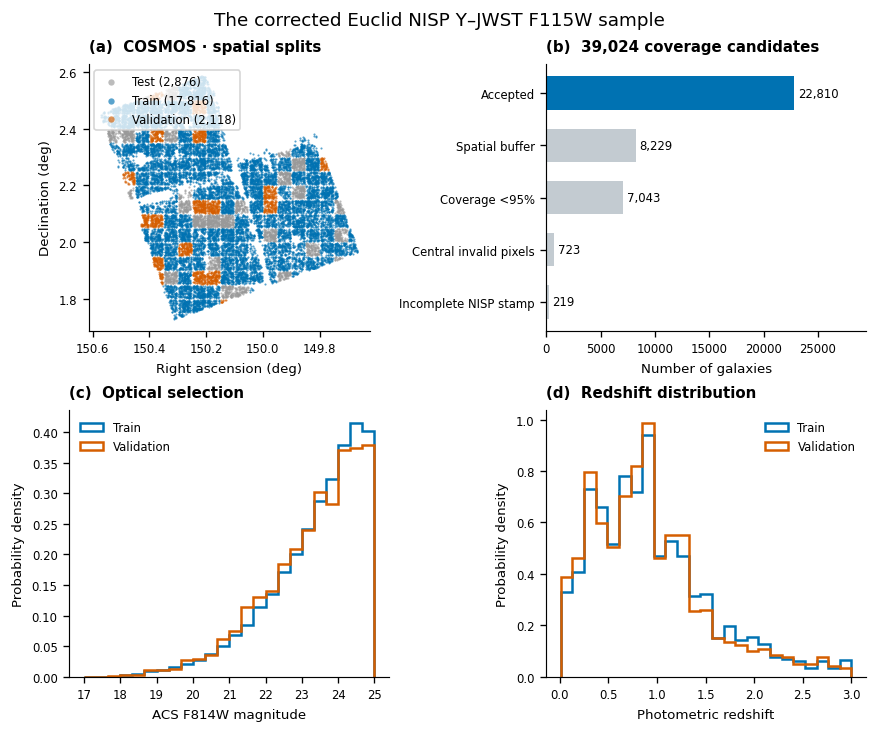

In [3]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE, layout='constrained')
ax = axes[0, 0]
for split in ['test', 'train', 'validation']:
    group = objects[objects.split == split]
    ax.scatter(group.ra, group.dec, s=1.6, alpha=.65, color=COLORS[split],
               linewidths=0, rasterized=True,
               label=f"{split.capitalize()} ({len(group):,})")
ax.set(xlabel='Right ascension (deg)', ylabel='Declination (deg)')
ax.invert_xaxis()
ax.set_aspect(1 / np.cos(np.deg2rad(objects.dec.mean())))
ax.legend(loc='upper left', markerscale=3, frameon=True, facecolor='white')
panel(ax, 'a', 'COSMOS · spatial splits')

ax = axes[0, 1]
labels = ['Accepted', 'Spatial buffer', 'Coverage <95%', 'Central invalid pixels', 'Incomplete NISP stamp']
values = [manifest['accepted'], manifest['rejection_counts']['spatial_buffer'],
          manifest['rejection_counts']['coverage_below_95_percent'],
          manifest['rejection_counts']['invalid_central_5_nisp_pixels'],
          manifest['rejection_counts']['Arrays overlap only partially.']]
ax.barh(np.arange(5), values, color=[COLORS['train']] + ['#C3CBD1'] * 4, height=.65)
for i, value in enumerate(values):
    ax.text(value + 350, i, f'{value:,}', va='center', fontsize=7)
ax.set_yticks(np.arange(5), labels)
ax.invert_yaxis()
ax.set_xlim(0, max(values) * 1.29)
ax.set_xlabel('Number of galaxies')
panel(ax, 'b', f"{manifest['candidates']:,} coverage candidates")

population = objects[objects.split.isin(PROPERTY_SPLITS)]
mag_bins = np.linspace(np.floor(population.ACS_F814W_MAG.min()), 25, 25)
z_bins = np.linspace(.01, 3, 26)
for ax, column, bins, xlabel, letter, title in [
    (axes[1, 0], 'ACS_F814W_MAG', mag_bins, 'ACS F814W magnitude', 'c', 'Optical selection'),
    (axes[1, 1], 'ez_z_phot', z_bins, 'Photometric redshift', 'd', 'Redshift distribution')]:
    for split in PROPERTY_SPLITS:
        data = objects.loc[objects.split == split, column].dropna()
        ax.hist(data, bins=bins, density=True, histtype='step', linewidth=1.5,
                color=COLORS[split], label=split.capitalize())
    ax.set(xlabel=xlabel, ylabel='Probability density')
    ax.legend(frameon=False)
    panel(ax, letter, title)
fig.suptitle('The corrected Euclid NISP Y–JWST F115W sample', fontsize=11)
plt.show()

In [4]:
paths = export(fig, f'fig01_sample_{VERSION}', '01_sample.ipynb',
               [manifest_path, objects_path],
               dict(figsize=FIGSIZE, property_splits=PROPERTY_SPLITS,
                    sample_count=len(objects), split_counts=manifest['split_counts'],
                    test_access='positions and counts only; no images or evaluation'),
               status='sample metadata layout draft')

Exported: fig01_sample_v01.pdf, fig01_sample_v01.svg, fig01_sample_v01.png


## Working caption

The corrected matched COSMOS sample. Accepted galaxies are divided into spatial
training, validation and reserved-test regions using 3-arcmin blocks and
10-arcsec boundary buffers. The accounting panel partitions the 39,024 existing
coverage candidates into accepted objects and extraction exclusions. The lower
panels show the magnitude and photometric-redshift distributions of training
and validation galaxies. This optically selected sample is not NISP-complete.

## Review together

- Does the footprint need survey mosaic boundaries, rather than points alone?
- Keep the accounting panel here, or move the exact cuts to a table?
- Is magnitude/redshift the right pair, or replace one with a well-defined size/SNR proxy?
- Catalog `FLUX_RADIUS` is not labeled in arcseconds without verifying its units.
- JWST coverage is a finite/nonzero SCI proxy; no JWST RMS/DQ was supplied.